# Import

In [58]:
import polars as pl
import numpy as np
import os
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import grangercausalitytests, adfuller
from scipy.stats import pearsonr, kendalltau, spearmanr
from scipy import signal


# Load data

In [59]:
def load_data(folder_path):
    print(f"Loading data from {folder_path}")
    # Lazily read all CSV files in the folder and return lazy DataFrame
    return pl.scan_csv(os.path.join(folder_path, "*.csv"))

current_path = os.getcwd()
binance_df = load_data(os.path.join(current_path, 'binance_data/eth-usdt'))
dex_df = load_data(os.path.join(current_path, 'dex_eth_usdt_jan_2025/treated'))

Loading data from /home/puguix/Documents/master-thesis/binance_data/eth-usdt
Loading data from /home/puguix/Documents/master-thesis/dex_eth_usdt_jan_2025/treated


# Convert timestamp to datetime and set as index for both dataframes 

In [60]:
binance_df = binance_df.with_columns(pl.from_epoch(pl.col('timestamp'), time_unit='ns').alias('timestamp'))

dex_df = dex_df.with_columns(pl.from_epoch(pl.col('timestamp'), time_unit='s').cast(pl.Datetime("ns")).alias('timestamp'))

# Sort both dataframes by their timestamp index

In [61]:
binance_df = binance_df.set_sorted('timestamp')
dex_df = dex_df.set_sorted('timestamp')

# Display basic information about the datasets

In [62]:
print("=== Binance Data Preview ===")
display(binance_df.head().collect())
display(binance_df.describe())

print("\n=== DEX Data Preview ===")
display(dex_df.head().collect())
display(dex_df.describe())

=== Binance Data Preview ===


timestamp,exchange,instrument,bid_1_price,bid_1_size,bid_2_price,bid_2_size,bid_3_price,bid_3_size,bid_4_price,bid_4_size,bid_5_price,bid_5_size,bid_6_price,bid_6_size,bid_7_price,bid_7_size,bid_8_price,bid_8_size,bid_9_price,bid_9_size,bid_10_price,bid_10_size,ask_1_price,ask_1_size,ask_2_price,ask_2_size,ask_3_price,ask_3_size,ask_4_price,ask_4_size,ask_5_price,ask_5_size,ask_6_price,ask_6_size,ask_7_price,ask_7_size,ask_8_price,ask_8_size,ask_9_price,ask_9_size,ask_10_price,ask_10_size
datetime[ns],str,str,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64
2025-01-01 00:00:05.016,"""binance""","""ethusdt""",3337410000000,2446400000,3337400000000,2000000,3337380000000,4700000,3337300000000,11500000,3337290000000,1572800000,3337280000000,791500000,3337230000000,1600000,3337220000000,2559500000,3337210000000,2012000000,3337190000000,182200000,3337420000000,50894400000,3337430000000,5838600000,3337440000000,10808000000,3337450000000,3500000,3337470000000,2000000,3337480000000,4305000000,3337490000000,1500000,3337540000000,1064500000,3337550000000,1894000000,3337560000000,2000000
2025-01-01 00:00:05.115,"""binance""","""ethusdt""",3337410000000,5113100000,3337400000000,2000000,3337380000000,4700000,3337330000000,1935800000,3337300000000,11500000,3337290000000,1572800000,3337280000000,791500000,3337230000000,1600000,3337220000000,100500000,3337210000000,2012000000,3337420000000,50899100000,3337430000000,5838600000,3337440000000,10808000000,3337450000000,3500000,3337470000000,2000000,3337480000000,4305000000,3337490000000,1500000,3337560000000,2000000,3337570000000,2000000,3337580000000,2000000
2025-01-01 00:00:05.215,"""binance""","""ethusdt""",3337290000000,10400000,3337280000000,793500000,3337230000000,3600000,3337220000000,3600000,3337210000000,2000000,3337180000000,2000000,3337140000000,3100000,3337120000000,9000000,3337090000000,1068900000,3337050000000,7400000,3337300000000,41848700000,3337320000000,3960400000,3337340000000,4952000000,3337350000000,1500000,3337390000000,181400000,3337400000000,2633000000,3337410000000,21506200000,3337420000000,10728100000,3337430000000,510200000,3337440000000,10809100000
2025-01-01 00:00:05.315,"""binance""","""ethusdt""",3337230000000,1559400000,3337220000000,8400000,3337180000000,2000000,3337140000000,4700000,3337120000000,10600000,3337050000000,7400000,3337020000000,3100000,3337000000000,299600000,3336990000000,50000000,3336940000000,3100000,3337240000000,39500900000,3337280000000,3958400000,3337290000000,27545900000,3337300000000,1022000000,3337320000000,2000000,3337340000000,4952000000,3337350000000,3500000,3337390000000,181900000,3337400000000,2633000000,3337410000000,599000000
2025-01-01 00:00:05.415,"""binance""","""ethusdt""",3337230000000,6963000000,3337180000000,2000000,3337140000000,4700000,3337120000000,9000000,3337050000000,7400000,3337020000000,4700000,3337000000000,1497600000,3336990000000,50000000,3336940000000,3100000,3336930000000,603700000,3337240000000,35063400000,3337280000000,16645800000,3337290000000,2000000,3337300000000,22000000,3337320000000,3500000,3337340000000,2000000,3337350000000,3500000,3337390000000,181900000,3337400000000,2635000000,3337410000000,599000000


statistic,timestamp,exchange,instrument,bid_1_price,bid_1_size,bid_2_price,bid_2_size,bid_3_price,bid_3_size,bid_4_price,bid_4_size,bid_5_price,bid_5_size,bid_6_price,bid_6_size,bid_7_price,bid_7_size,bid_8_price,bid_8_size,bid_9_price,bid_9_size,bid_10_price,bid_10_size,ask_1_price,ask_1_size,ask_2_price,ask_2_size,ask_3_price,ask_3_size,ask_4_price,ask_4_size,ask_5_price,ask_5_size,ask_6_price,ask_6_size,ask_7_price,ask_7_size,ask_8_price,ask_8_size,ask_9_price,ask_9_size,ask_10_price,ask_10_size
str,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""","""25562014""","""25562014""","""25562014""",2.5562014e7,2.5562014e7,2.5562014e7,2.5562014e7,2.5562014e7,2.5562014e7,2.5562014e7,2.5562014e7,2.5562014e7,2.5562014e7,2.5562014e7,2.5562014e7,2.5562014e7,2.5562014e7,2.5562014e7,2.5562014e7,2.5562014e7,2.5562014e7,2.5562014e7,2.5562014e7,2.5562014e7,2.5562014e7,2.5562014e7,2.5562014e7,2.5562014e7,2.5562014e7,2.5562014e7,2.5562014e7,2.5562014e7,2.5562014e7,2.5562014e7,2.5562014e7,2.5562014e7,2.5562014e7,2.5562014e7,2.5562014e7,2.5562014e7,2.5562014e7,2.5562014e7,2.5562014e7
"""null_count""","""0""","""0""","""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""","""2025-01-16 09:52:47.966170""",null,null,3.3318e12,3.2589e10,3.3317e12,2.0284e9,3.3317e12,1.4519e9,3.3317e12,1.2478e9,3.3317e12,1.1454e9,3.3317e12,1.3270e9,3.3316e12,1.4627e9,3.3316e12,1.6033e9,3.3316e12,1.7240e9,3.3316e12,1.8367e9,3.3318e12,3.3910e10,3.3318e12,2.0822e9,3.3318e12,1.3937e9,3.3318e12,1.2013e9,3.3318e12,1.0481e9,3.3318e12,1.1189e9,3.3319e12,1.1773e9,3.3319e12,1.2230e9,3.3319e12,1.3306e9,3.3319e12,1.4394e9
"""std""",null,null,null,1.4915e11,3.3068e10,1.4915e11,9.4384e9,1.4915e11,7.3505e9,1.4915e11,5.3552e9,1.4915e11,5.7299e9,1.4915e11,5.5648e9,1.4915e11,5.8662e9,1.4915e11,7.9349e9,1.4915e11,7.5201e9,1.4915e11,7.6769e9,1.4915e11,3.7185e10,1.4915e11,1.0821e10,1.4915e11,7.3375e9,1.4915e11,5.7512e9,1.4915e11,5.7857e9,1.4915e11,6.7874e9,1.4915e11,7.9674e9,1.4915e11,6.6621e9,1.4915e11,7.0549e9,1.4915e11,7.3413e9
"""min""","""2025-01-01 00:00:05.016000""","""binance""","""ethusdt""",2.9200e12,100000.0,2.9200e12,100000.0,2.9200e12,100000.0,2.9200e12,100000.0,2.9199e12,100000.0,2.9199e12,100000.0,2.9199e12,100000.0,2.9199e12,100000.0,2.9198e12,100000.0,2.9198e12,100000.0,2.9202e12,100000.0,2.9237e12,100000.0,2.9256e12,100000.0,2.9256e12,100000.0,2.9258e12,100000.0,2.9258e12,100000.0,2.9258e12,100000.0,2.9259e12,100000.0,2.9259e12,100000.0,2.9261e12,100000.0
"""25%""","""2025-01-08 16:58:53.615000""",null,null,3.2395e12,9.2289e9,3.2395e12,3.6e6,3.2395e12,3e6,3.2395e12,3.2e6,3.2395e12,3.1e6,3.2394e12,1.8e6,3.2394e12,2.9e6,3.2394e12,3.1e6,3.2394e12,3.2e6,3.2394e12,3.3e6,3.2396e12,9.3156e9,3.2396e12,4.7e6,3.2396e12,4.7e6,3.2396e12,4.7e6,3.2396e12,4.6e6,3.2396e12,2e6,3.2396e12,2e6,3.2397e12,2e6,3.2397e12,2e6,3.2397e12,2e6
"""50%""","""2025-01-16 06:02:37.415000""",null,null,3.3070e12,2.5023e10,3.3070e12,3.05e7,3.3070e12,6.6e6,3.3070e12,6.4e6,3.3069e12,6.4e6,3.3069e12,2.95e7,3.3069e12,1.012e8,3.3069e12,2.5e8,3.3068e12,3.752e8,3.3068e12,5.143e8,3.3070e12,2.6013e10,3.3070e12,1.06e7,3.3070e12,6.6e6,3.3070e12,6.6e6,3.3071e12,6.4e6,3.3071e12,4.7e6,3.3071e12,4.9e6,3.3071e12,5.1e6,3.3071e12,6.5e6,3.3071e12,1.22e7
"""75%""","""2025-01-24 05:35:49.515000""",null,null,3.3906e12,4.7847e10,3.3906e12,1.8540e9,3.3906e12,1.3271e9,3.3906e12,9.996e8,3.3905e12,7.909e8,3.3905e12,1.2620e9,3.3905e12,1.5026e9,3.3905e12,1.7817e9,3.3905e12,1.9616e9,3.3904e12,2.1606e9,3.3906e12,4.9825e10,3.3906e12,1.8367e9,3.3907e12,1.0046e9,3.3907e12,6.606e8,3.3907e12,5.785e8,3.3907e12,6.522e8,3.3907e12,7.778e8,3.3907e12,1.0172e9,3.3908e12,1.2257e9,3.3908e12,1.4657e9
"""max""","""2025-01-31 23:59:59.915000""","""binance""","""ethusdt""",3.7446e12,2.5948e12,3.7446e12


=== DEX Data Preview ===


eth_reserves,usdt_reserves,timestamp,eth_usdt
f64,f64,datetime[ns],f64
1.0389e22,3.4705e13,2024-12-31 22:58:23,3.3405e12
1.0389e22,3.4706e13,2024-12-31 23:03:11,3.3406e12
1.0389e22,3.4706e13,2024-12-31 23:04:23,3.3406e12
1.0389e22,3.4706e13,2024-12-31 23:04:59,3.3406e12
1.0391e22,3.4699e13,2024-12-31 23:05:11,3.3392e12


statistic,eth_reserves,usdt_reserves,timestamp,eth_usdt
str,f64,f64,str,f64
"""count""",59827.0,59827.0,"""59827""",59827.0
"""null_count""",0.0,0.0,"""0""",0.0
"""mean""",1.0909e22,3.6352e13,"""2025-01-16 00:32:15.923997""",3.3367e12
"""std""",1.5214e21,4.9275e12,null,1.5314e11
"""min""",8.3814e21,2.7099e13,"""2024-12-31 22:58:23""",2.9341e12
"""25%""",1.0210e22,3.3825e13,"""2025-01-08 10:30:47""",3.2425e12
"""50%""",1.0398e22,3.4722e13,"""2025-01-16 03:48:11""",3.3095e12
"""75%""",1.0703e22,3.6476e13,"""2025-01-23 02:15:23""",3.3992e12
"""max""",1.5060e22,4.8385e13,"""2025-01-31 22:58:35""",3.7359e12


# Align the timestamps of both dataframes

In [63]:
# Find the latest start time and earliest end time between both datasets
start_time = pl.col('timestamp').min().alias('min_time')
end_time = pl.col('timestamp').max().alias('max_time')

start_time = max(binance_df.select(start_time).collect().item(), dex_df.select(start_time).collect().item())
end_time = min(binance_df.select(end_time).collect().item(), dex_df.select(end_time).collect().item())

# Trim both dataframes to the common time period
binance_df = binance_df.filter(pl.col('timestamp').is_between(start_time, end_time))
dex_df = dex_df.filter(pl.col('timestamp').is_between(start_time, end_time))

print("\n=== Time Range After Alignment ===")
print(f"Start time: {start_time}")
print(f"End time: {end_time}")


=== Time Range After Alignment ===
Start time: 2025-01-01 00:00:05.016000
End time: 2025-01-31 22:58:35


# Calculate mid price for Binance

In [64]:
binance_df = binance_df.with_columns(
    ((pl.col('bid_1_price') + pl.col('ask_1_price')) / 2).alias('mid_price')
)

# Plot the data

/tmp/ipykernel_14781/3751326710.py:18: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
/home/puguix/Documents/master-thesis/venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


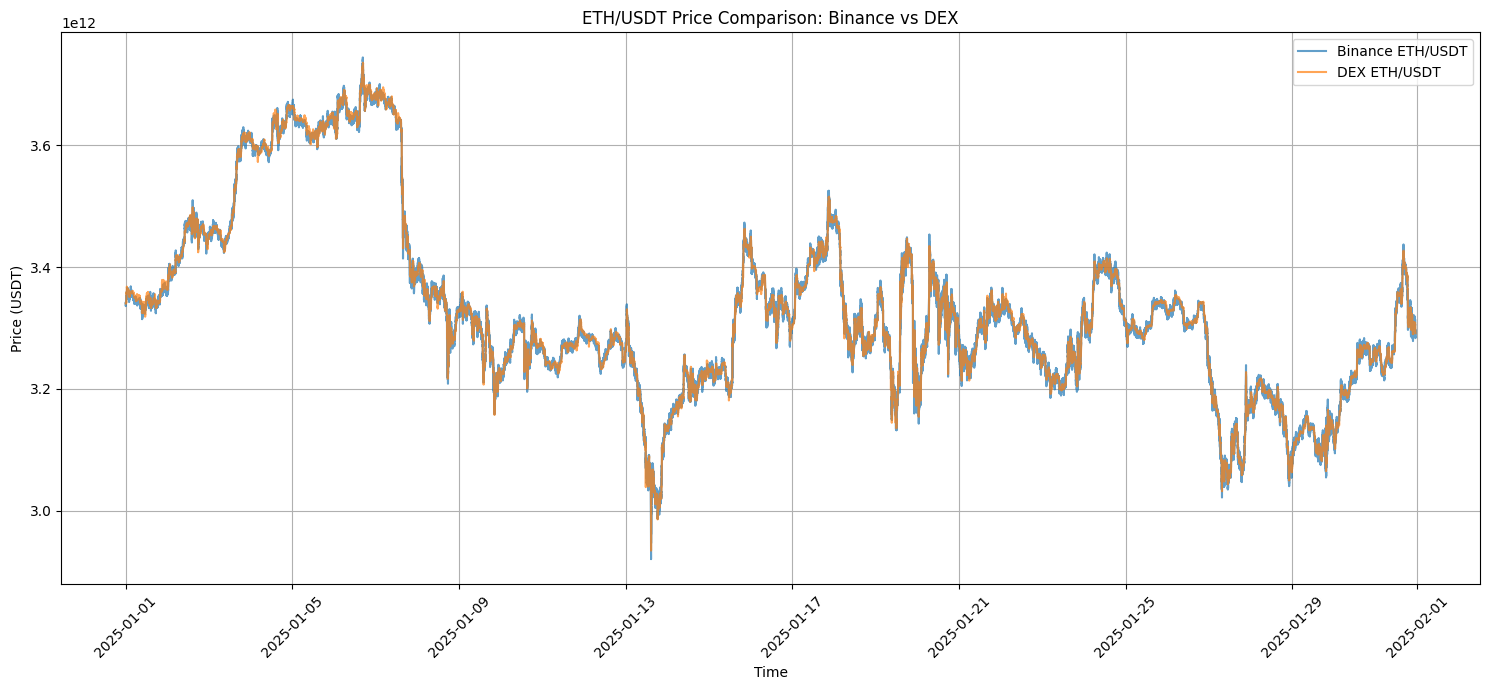

In [65]:
plt.figure(figsize=(15, 7))

# Plot Binance data
plt.plot(binance_df.select('timestamp').collect(), binance_df.select('mid_price').collect(), label='Binance ETH/USDT', alpha=0.7)

# Plot DEX data 
plt.plot(dex_df.select('timestamp').collect(), dex_df.select('eth_usdt').collect(), label='DEX ETH/USDT', alpha=0.7)

plt.title('ETH/USDT Price Comparison: Binance vs DEX')
plt.xlabel('Time')
plt.ylabel('Price (USDT)')
plt.legend()
plt.grid(True)

# Rotate x-axis labels for better readability
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


# Calculate cross-correlation between Binance mid returns and DEX returns using the Hayashi-Yoshida estimator
Ticks are not the same, so we need to use the Hayashi-Yoshida estimator to calculate the cross-correlation.

To estimate the cross-correlation function with a lag ($\ell$), a lagged version of the estimator is used:

$\hat{\rho}(\ell) = \frac{\sum_{i,j} r^X_i r^Y_j 1_{{O^\ell_{ij} \neq \emptyset}}}{\sqrt{\sum_i (r^X_i)^2 \sum_j (r^Y_j)^2}}$

where $O^\ell_{ij} = ]t_{i-1}, t_i] \cap ]s_{j-1} - \ell, s_j - \ell]$ represents the time interval between the $i$-th transaction of asset X and the lagged time interval of the $j$-th transaction of asset Y.

In [26]:
# Compute log returns
binance_returns_df = binance_df.select([
    pl.col("timestamp"),
    pl.col("mid_price").log().diff().alias("binance_returns")
]).filter(pl.col("binance_returns").is_not_null())

dex_returns_df = dex_df.select([
    pl.col("timestamp"),
    pl.col("eth_usdt").log().diff().alias("dex_returns")
]).filter(pl.col("dex_returns").is_not_null())

lags = np.arange(-20, 21)
lag_ns_list = lags * 1_000_000_000 

# Build correlation computations for each lag
corr_exprs = []

for lag, lag_ns in zip(lags, lag_ns_list):
    # Shift DEX timestamps by lag
    shifted_dex = dex_returns_df.select([
        (pl.col("timestamp").cast(pl.Int64) + lag_ns).cast(pl.Datetime("ns")).alias("timestamp"),
        pl.col("dex_returns")
    ])
    
    # Join on nearest timestamp (asynchronous-safe)
    joined = binance_returns_df.join_asof(
        shifted_dex,
        on="timestamp",
        strategy="nearest"
    ).select(
        pl.corr("binance_returns", "dex_returns").alias(f"lag_{lag}")
    )

    corr_exprs.append(joined)

# Combine all correlation results
lazy_corrs = pl.concat(corr_exprs, how="horizontal")

# Collect the result
result_row = lazy_corrs.collect(engine='streaming').row(0)

# Turn into a tidy DataFrame with lag/correlation
lag_corrs = pl.DataFrame({
    "lag": lags,
    "correlation": result_row
})

lag_corrs.transpose()

# Plot results

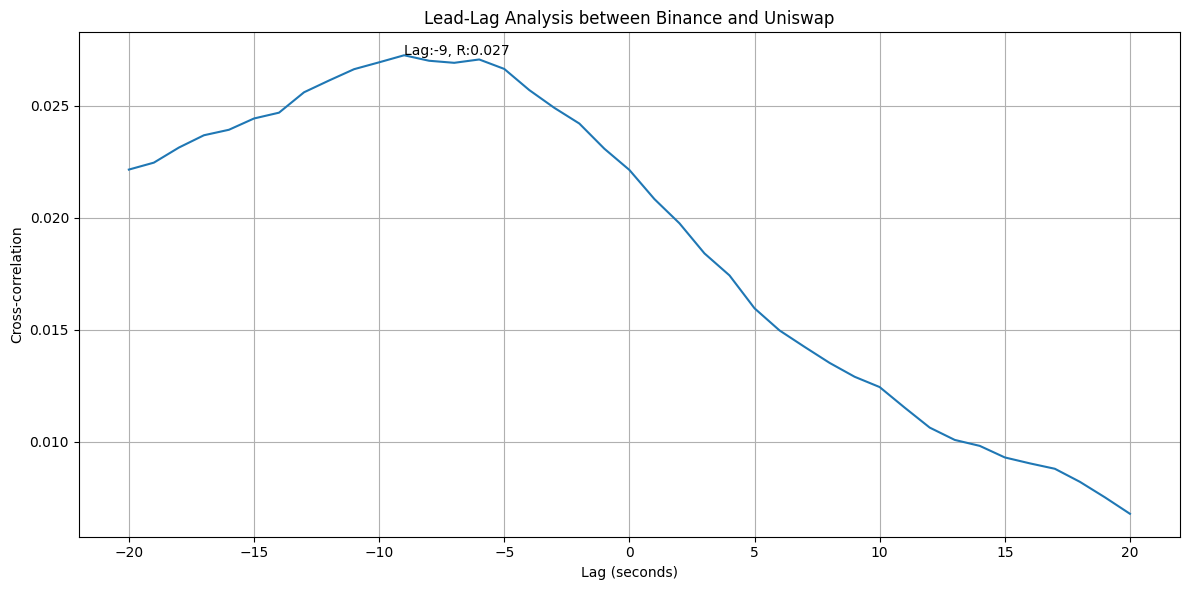

In [28]:
plt.figure(figsize=(12, 6))
plt.plot(lag_corrs['lag'], lag_corrs['correlation'])

# Add annotation for maximum correlation
max_corr = lag_corrs['correlation'].max()
max_lag = lag_corrs.filter(pl.col('correlation') == max_corr)['lag'][0]
plt.annotate(f'Lag:{max_lag}, R:{max_corr:.3f}', xy=(max_lag, max_corr))

plt.xlabel('Lag (seconds)')
plt.ylabel('Cross-correlation')
plt.title('Lead-Lag Analysis between Binance and Uniswap')
plt.grid(True)

plt.tight_layout()
plt.show()


Here we can see a first time that Binance leads Uniswap.

# Calculate lead/lag ratio

In [29]:
lead_lag_ratio = (
    lag_corrs.lazy()
    .with_columns([
        pl.when(pl.col("lag") > 0).then(pl.col("correlation") ** 2).otherwise(0.0).alias("lead_power_term"),
        pl.when(pl.col("lag") < 0).then(pl.col("correlation") ** 2).otherwise(0.0).alias("lag_power_term"),
    ])
    .select([
        pl.sum("lead_power_term").alias("lead_power"),
        pl.sum("lag_power_term").alias("lag_power"),
    ])
    .with_columns([
        (pl.col("lead_power") / pl.col("lag_power")).alias("lead_lag_ratio")
    ])
    .collect()
)

lead_lag_ratio


lead_power,lag_power,lead_lag_ratio
f64,f64,f64
0.003508,0.012679,0.276695


The lead component is about 3.6 times stronger than the lag component: price discovery primarily occurs on Binance.

# Perform Granger causality tests in both directions  

The trick is that we need the same frequency for both series. To do so, we will downsample the Binance data to the DEX frequency, with a weigthed moving average.

In [ ]:
window_size = 30

# Create a weighted moving average on binance_returns
binance_weighted_avg = (
    binance_returns_df
    .sort("timestamp")
    .with_columns([
        pl.col("binance_returns").rolling_mean(
            window_size=window_size,
            weights=list(range(1, window_size+1)),  # Increasing weights for more recent values
            min_samples=1
        ).alias("binance_returns_weighted"),
        pl.col("binance_returns").rolling_mean(
            window_size=window_size,
            min_samples=1
        ).alias("binance_returns_mean")
    ])
)

# Join DEX data with the weighted Binance data
granger_df = dex_returns_df.join_asof(
    binance_weighted_avg,
    on="timestamp",
    strategy="backward"  # get last Binance row before each DEX ts
)

granger_df.head().collect(engine='streaming')

timestamp,dex_returns,binance_returns,binance_returns_weighted,binance_returns_mean
datetime[ns],f64,f64,f64,f64
2025-01-01 00:01:59,0.00001,0.0,0.000005,0.000005
2025-01-01 00:04:47,-7.9440e-7,0.0,0.0,0.0
2025-01-01 00:06:23,7.2474e-7,0.0,1.0945e-7,9.9790e-8
2025-01-01 00:06:35,0.000024,0.0,0.000005,0.000003
2025-01-01 00:06:47,0.00006,0.0,0.000003,0.000008


In [56]:
maxlag = 20  # Testing up to 20 lags

# Test if Binance Granger-causes DEX
print("Testing if Binance Granger-causes DEX:")
gc_binance_dex = grangercausalitytests(granger_df.select(['dex_returns', 'binance_returns']).collect(engine='streaming'), maxlag=maxlag)

# Test if DEX Granger-causes Binance
print("\nTesting if DEX Granger-causes Binance:")
gc_dex_binance = grangercausalitytests(granger_df.select(['binance_returns', 'dex_returns']).collect(engine='streaming'), maxlag=maxlag)

# Test if Binance (weighted) Granger-causes DEX
print("\nTesting if Binance (weighted) Granger-causes DEX:")
gc_binance_weighted_dex = grangercausalitytests(granger_df.select(['dex_returns', 'binance_returns_weighted']).collect(engine='streaming'), maxlag=maxlag)

# Test if DEX Granger-causes Binance (weighted)
print("\nTesting if DEX Granger-causes Binance (weighted):")
gc_dex_binance_weighted = grangercausalitytests(granger_df.select(['binance_returns_weighted', 'dex_returns']).collect(engine='streaming'), maxlag=maxlag)

# Test if Binance (mean) Granger-causes DEX
print("\nTesting if Binance (mean) Granger-causes DEX:")
gc_binance_mean_dex = grangercausalitytests(granger_df.select(['dex_returns', 'binance_returns_mean']).collect(engine='streaming'), maxlag=maxlag)

# Test if DEX Granger-causes Binance (mean)
print("\nTesting if DEX Granger-causes Binance (mean):")
gc_dex_binance_mean = grangercausalitytests(granger_df.select(['binance_returns_mean', 'dex_returns']).collect(engine='streaming'), maxlag=maxlag)
# Find the minimum p-value for each test across all lags (lower p-value = stronger evidence of causality)
min_binance_dex_pval = min((gc_binance_dex[lag][0]['ssr_chi2test'][1], lag) for lag in range(1, maxlag+1))
min_dex_binance_pval = min((gc_dex_binance[lag][0]['ssr_chi2test'][1], lag) for lag in range(1, maxlag+1))
min_binance_weighted_dex_pval = min((gc_binance_weighted_dex[lag][0]['ssr_chi2test'][1], lag) for lag in range(1, maxlag+1))
min_dex_binance_weighted_pval = min((gc_dex_binance_weighted[lag][0]['ssr_chi2test'][1], lag) for lag in range(1, maxlag+1))
min_binance_mean_dex_pval = min((gc_binance_mean_dex[lag][0]['ssr_chi2test'][1], lag) for lag in range(1, maxlag+1))
min_dex_binance_mean_pval = min((gc_dex_binance_mean[lag][0]['ssr_chi2test'][1], lag) for lag in range(1, maxlag+1))

# Store the results with both p-value and corresponding lag
all_pvals = {
    "Binance (unweighted) -> DEX": min_binance_dex_pval,
    "DEX -> Binance (unweighted)": min_dex_binance_pval,
    "Binance (weighted) -> DEX": min_binance_weighted_dex_pval,
    "DEX -> Binance (weighted)": min_dex_binance_weighted_pval,
    "Binance (mean) -> DEX": min_binance_mean_dex_pval,
    "DEX -> Binance (mean)": min_dex_binance_mean_pval
}

strongest_link = min(all_pvals.items(), key=lambda x: x[1][0])

# Print the strongest causal relationship with lag
print("\nStrongest Granger causal relationship:")
print(f"{strongest_link[0]} with p-value: {strongest_link[1][0]} at lag {strongest_link[1][1]}")

# Print all p-values for comparison with their corresponding lags
print("\nAll minimum p-values across lags (lower = stronger evidence):")
for relationship, (p_value, lag) in sorted(all_pvals.items(), key=lambda x: x[1][0]):
    print(f"{relationship}: p-value = {p_value} at lag {lag}")

Testing if Binance Granger-causes DEX:

Granger Causality
number of lags (no zero) 1
ssr based F test:         F=12.6410 , p=0.0004  , df_denom=59767, df_num=1
ssr based chi2 test:   chi2=12.6417 , p=0.0004  , df=1
likelihood ratio test: chi2=12.6403 , p=0.0004  , df=1
parameter F test:         F=12.6410 , p=0.0004  , df_denom=59767, df_num=1

Granger Causality
number of lags (no zero) 2
ssr based F test:         F=31.3489 , p=0.0000  , df_denom=59764, df_num=2
ssr based chi2 test:   chi2=62.7031 , p=0.0000  , df=2
likelihood ratio test: chi2=62.6702 , p=0.0000  , df=2
parameter F test:         F=31.3489 , p=0.0000  , df_denom=59764, df_num=2

Granger Causality
number of lags (no zero) 3
ssr based F test:         F=20.1198 , p=0.0000  , df_denom=59761, df_num=3
ssr based chi2 test:   chi2=60.3665 , p=0.0000  , df=3
likelihood ratio test: chi2=60.3360 , p=0.0000  , df=3
parameter F test:         F=20.1198 , p=0.0000  , df_denom=59761, df_num=3

Granger Causality
number of lags (no zero)

# Perform Augmented Dickey-Fuller test on both return series

Can't perform the ADF test on the all binance returns, because the data is too large.

In [39]:
# ADF test for DEX returns
dex_returns_adf = adfuller(dex_returns_df.select('dex_returns').collect(engine='streaming'))
print("ADF Test for DEX Returns:")
print(f"ADF Statistic: {dex_returns_adf[0]}")
print(f"p-value: {dex_returns_adf[1]}")
print(f"Critical Values:")
for key, value in dex_returns_adf[4].items():
    print(f"\t{key}: {value}")
print(f"{'Stationary' if dex_returns_adf[1] < 0.05 else 'Non-stationary'} (at 5% significance level)")

ADF Test for DEX Returns:
ADF Statistic: -31.522008737362363
p-value: 0.0
Critical Values:
	1%: -3.4304595168746097
	5%: -2.8615884043829163
	10%: -2.5667957640219328
Stationary (at 5% significance level)


In [57]:
# ADF test for mean Binance returns
binance_adf = adfuller(granger_df.select('binance_returns').collect(engine='streaming'))
print("ADF Test for Mean Binance Returns:")
print(f"ADF Statistic: {binance_adf[0]}")
print(f"p-value: {binance_adf[1]}")
print(f"Critical Values:")
for key, value in binance_adf[4].items():
    print(f"\t{key}: {value}")
print(f"{'Stationary' if binance_adf[1] < 0.05 else 'Non-stationary'} (at 5% significance level)")


ADF Test for Mean Binance Returns:
ADF Statistic: -30.05959832619404
p-value: 0.0
Critical Values:
	1%: -3.4304595168746097
	5%: -2.8615884043829163
	10%: -2.5667957640219328
Stationary (at 5% significance level)


In [55]:
# ADF test for mean Binance returns mean
binance_mean_adf = adfuller(granger_df.select('binance_returns_mean').collect(engine='streaming'))
print("ADF Test for Mean Binance Returns:")
print(f"ADF Statistic: {binance_mean_adf[0]}")
print(f"p-value: {binance_mean_adf[1]}")
print(f"Critical Values:")
for key, value in binance_mean_adf[4].items():
    print(f"\t{key}: {value}")
print(f"{'Stationary' if binance_mean_adf[1] < 0.05 else 'Non-stationary'} (at 5% significance level)")


ADF Test for Mean Binance Returns:
ADF Statistic: -29.211811501126256
p-value: 0.0
Critical Values:
	1%: -3.430459520542999
	5%: -2.8615884060042447
	10%: -2.5667957648849167
Stationary (at 5% significance level)


In [38]:
# ADF test for weighted Binance returns
binance_weighted_adf = adfuller(granger_df.select('binance_returns_weighted').collect(engine='streaming'))
print("ADF Test for Weighted Binance Returns:")
print(f"ADF Statistic: {binance_weighted_adf[0]}")
print(f"p-value: {binance_weighted_adf[1]}")
print(f"Critical Values:")
for key, value in binance_weighted_adf[4].items():
    print(f"\t{key}: {value}")
print(f"{'Stationary' if binance_weighted_adf[1] < 0.05 else 'Non-stationary'} (at 5% significance level)")


ADF Test for Weighted Binance Returns:
ADF Statistic: -29.382247266188315
p-value: 0.0
Critical Values:
	1%: -3.4304595168746097
	5%: -2.8615884043829163
	10%: -2.5667957640219328
Stationary (at 5% significance level)


# Perform Pearson correlation test between DEX and Binance returns

In [43]:
corr_dex_binance, p_value_dex_binance = pearsonr(granger_df.select('dex_returns').collect(engine='streaming'), granger_df.select('binance_returns').collect(engine='streaming'))
corr_dex_binance_weighted, p_value_dex_binance_weighted = pearsonr(granger_df.select('dex_returns').collect(engine='streaming'), granger_df.select('binance_returns_weighted').collect(engine='streaming'))
corr_dex_binance_mean, p_value_dex_binance_mean = pearsonr(granger_df.select('dex_returns').collect(engine='streaming'), granger_df.select('binance_returns_mean').collect(engine='streaming'))

# Print results
print("\nPearson Correlation Test Results:")
print(f"DEX vs Binance Returns:")
print(f"  Correlation coefficient: {float(corr_dex_binance[0]):.6f}")
print(f"  p-value: {float(p_value_dex_binance[0]):.6f}")
print(f"  {'Significant' if float(p_value_dex_binance[0]) < 0.05 else 'Not significant'} correlation at 5% level")

print(f"\nDEX vs Weighted Binance Returns:")
print(f"  Correlation coefficient: {float(corr_dex_binance_weighted[0]):.6f}")
print(f"  p-value: {float(p_value_dex_binance_weighted[0]):.6f}")
print(f"  {'Significant' if float(p_value_dex_binance_weighted[0]) < 0.05 else 'Not significant'} correlation at 5% level")

print(f"\nDEX vs Mean Binance Returns:")
print(f"  Correlation coefficient: {float(corr_dex_binance_mean[0]):.6f}")
print(f"  p-value: {float(p_value_dex_binance_mean[0]):.6f}")
print(f"  {'Significant' if float(p_value_dex_binance_mean[0]) < 0.05 else 'Not significant'} correlation at 5% level")



Pearson Correlation Test Results:
DEX vs Binance Returns:
  Correlation coefficient: 0.077619
  p-value: 0.000000
  Significant correlation at 5% level

DEX vs Weighted Binance Returns:
  Correlation coefficient: 0.222469
  p-value: 0.000000
  Significant correlation at 5% level


# Perform Kendall rank correlation test between DEX and Binance returns

In [46]:
kendall_dex_binance, p_value_kendall_dex_binance = kendalltau(
    granger_df.select('dex_returns').collect(engine='streaming'), 
    granger_df.select('binance_returns').collect(engine='streaming')
)

kendall_dex_binance_weighted, p_value_kendall_dex_binance_weighted = kendalltau(
    granger_df.select('dex_returns').collect(engine='streaming'), 
    granger_df.select('binance_returns_weighted').collect(engine='streaming')
)

kendall_dex_binance_mean, p_value_kendall_dex_binance_mean = kendalltau(
    granger_df.select('dex_returns').collect(engine='streaming'), 
    granger_df.select('binance_returns_mean').collect(engine='streaming')
)

print("\nKendall Rank Correlation Test Results:")
print(f"DEX vs Binance Returns:")
print(f"  Correlation coefficient: {kendall_dex_binance:.6f}")
print(f"  p-value: {p_value_kendall_dex_binance:.6f}")
print(f"  {'Significant' if p_value_kendall_dex_binance < 0.05 else 'Not significant'} correlation at 5% level")

print(f"\nDEX vs Weighted Binance Returns:")
print(f"  Correlation coefficient: {kendall_dex_binance_weighted:.6f}")
print(f"  p-value: {p_value_kendall_dex_binance_weighted:.6f}")
print(f"  {'Significant' if p_value_kendall_dex_binance_weighted < 0.05 else 'Not significant'} correlation at 5% level")

print(f"\nDEX vs Mean Binance Returns:")
print(f"  Correlation coefficient: {kendall_dex_binance_mean:.6f}")
print(f"  p-value: {p_value_kendall_dex_binance_mean:.6f}")
print(f"  {'Significant' if p_value_kendall_dex_binance_mean < 0.05 else 'Not significant'} correlation at 5% level")



Kendall Rank Correlation Test Results:
DEX vs Binance Returns:
  Correlation coefficient: 0.017029
  p-value: 0.000000
  Significant correlation at 5% level

DEX vs Weighted Binance Returns:
  Correlation coefficient: 0.052859
  p-value: 0.000000
  Significant correlation at 5% level


# Calculate Spearman rank correlation for DEX vs Binance returns

In [47]:
spearman_dex_binance, p_value_spearman_dex_binance = spearmanr(
    granger_df.select('dex_returns').collect(engine='streaming'), 
    granger_df.select('binance_returns').collect(engine='streaming')
)

# Calculate Spearman rank correlation for DEX vs weighted Binance returns
spearman_dex_binance_weighted, p_value_spearman_dex_binance_weighted = spearmanr(
    granger_df.select('dex_returns').collect(engine='streaming'), 
    granger_df.select('binance_returns_weighted').collect(engine='streaming')
)

# Calculate Spearman rank correlation for DEX vs mean Binance returns
spearman_dex_binance_mean, p_value_spearman_dex_binance_mean = spearmanr(
    granger_df.select('dex_returns').collect(engine='streaming'), 
    granger_df.select('binance_returns_mean').collect(engine='streaming')
)

# Print results
print("\nSpearman Rank Correlation Test Results:")
print(f"DEX vs Binance Returns:")
print(f"  Correlation coefficient: {spearman_dex_binance:.6f}")
print(f"  p-value: {p_value_spearman_dex_binance:.6f}")
print(f"  {'Significant' if p_value_spearman_dex_binance < 0.05 else 'Not significant'} correlation at 5% level")

print(f"\nDEX vs Weighted Binance Returns:")
print(f"  Correlation coefficient: {spearman_dex_binance_weighted:.6f}")
print(f"  p-value: {p_value_spearman_dex_binance_weighted:.6f}")
print(f"  {'Significant' if p_value_spearman_dex_binance_weighted < 0.05 else 'Not significant'} correlation at 5% level")

print(f"\nDEX vs Mean Binance Returns:")
print(f"  Correlation coefficient: {spearman_dex_binance_mean:.6f}")
print(f"  p-value: {p_value_spearman_dex_binance_mean:.6f}")
print(f"  {'Significant' if p_value_spearman_dex_binance_mean < 0.05 else 'Not significant'} correlation at 5% level")



Spearman Rank Correlation Test Results:
DEX vs Binance Returns:
  Correlation coefficient: 0.021319
  p-value: 0.000000
  Significant correlation at 5% level

DEX vs Weighted Binance Returns:
  Correlation coefficient: 0.075453
  p-value: 0.000000
  Significant correlation at 5% level


# Perform spectral analysis and coherence calculation

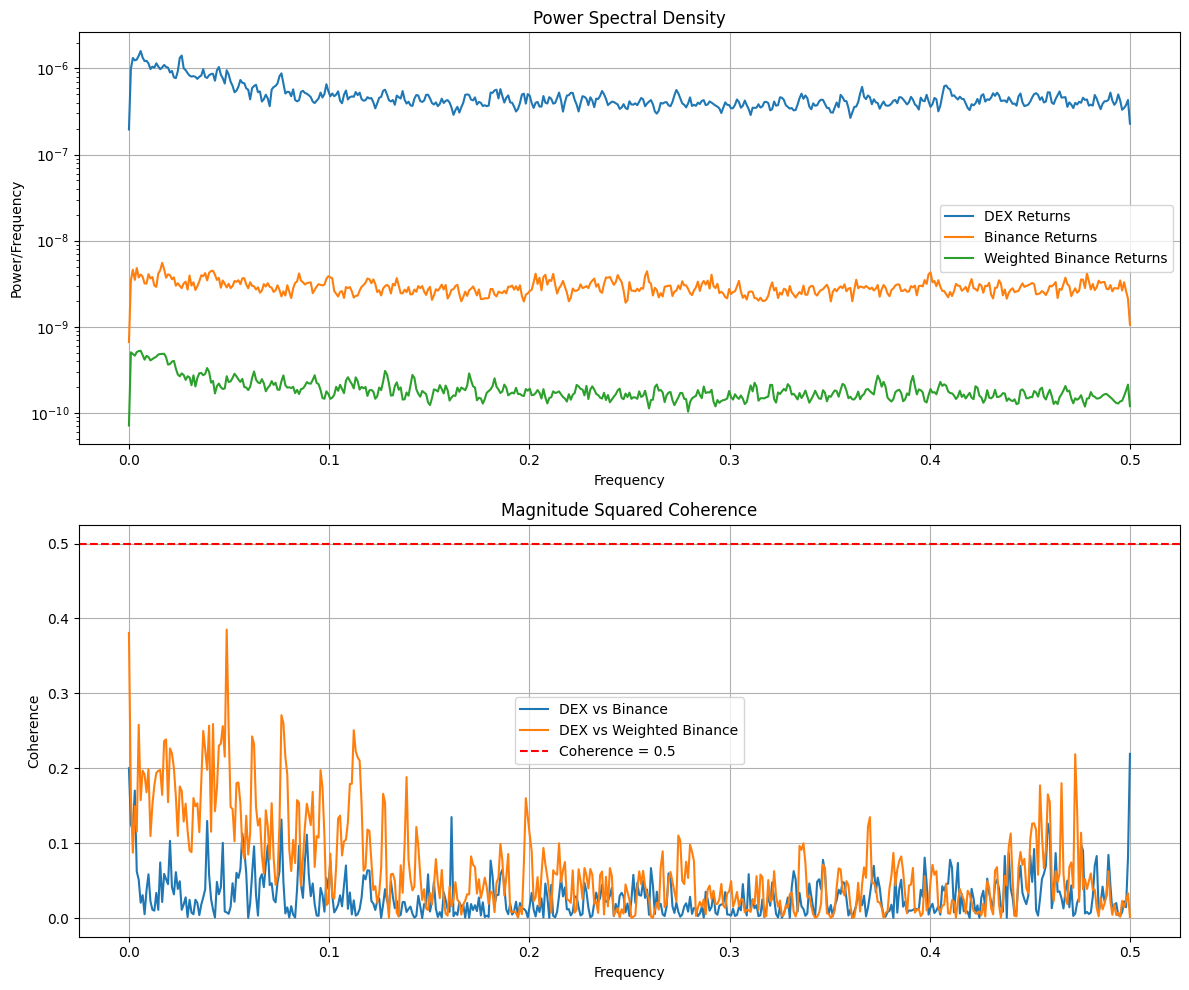


Average Coherence in Different Frequency Bands:
DEX vs Binance:
  Low frequency (0-0.1): 0.0420
  Mid frequency (0.1-0.3): 0.0212
  High frequency (0.3+): 0.0292

DEX vs Weighted Binance:
  Low frequency (0-0.1): 0.1545
  Mid frequency (0.1-0.3): 0.0517
  High frequency (0.3+): 0.0397

Frequency with Maximum Coherence:
DEX vs Binance: 0.500000 (Coherence: 0.2192)
DEX vs Weighted Binance: 0.048828 (Coherence: 0.3852)


In [ ]:
# Extract the return series
dex_returns = np.array(granger_df.select('dex_returns').collect(engine='streaming')).flatten()
binance_returns = np.array(granger_df.select('binance_returns').collect(engine='streaming')).flatten()
binance_returns_weighted = np.array(granger_df.select('binance_returns_weighted').collect(engine='streaming')).flatten()
binance_returns_mean = np.array(granger_df.select('binance_returns_mean').collect(engine='streaming')).flatten()

# Calculate power spectral density for each series
f_dex, psd_dex = signal.welch(dex_returns, nperseg=1024)
f_binance, psd_binance = signal.welch(binance_returns, nperseg=1024)
f_binance_weighted, psd_binance_weighted = signal.welch(binance_returns_weighted, nperseg=1024)
f_binance_mean, psd_binance_mean = signal.welch(binance_returns_mean, nperseg=1024)

# Calculate coherence between DEX and Binance returns
f_coh, coherence = signal.coherence(dex_returns, binance_returns, nperseg=1024)
f_coh_weighted, coherence_weighted = signal.coherence(dex_returns, binance_returns_weighted, nperseg=1024)
f_coh_mean, coherence_mean = signal.coherence(dex_returns, binance_returns_mean, nperseg=1024)

# Plot the power spectral densities
plt.figure(figsize=(12, 10))

# PSD plots
plt.subplot(2, 1, 1)
plt.semilogy(f_dex, psd_dex, label='DEX Returns')
plt.semilogy(f_binance, psd_binance, label='Binance Returns')
plt.semilogy(f_binance_weighted, psd_binance_weighted, label='Weighted Binance Returns')
plt.semilogy(f_binance_mean, psd_binance_mean, label='Mean Binance Returns')
plt.title('Power Spectral Density')
plt.xlabel('Frequency')
plt.ylabel('Power/Frequency')
plt.legend()
plt.grid(True)

# Coherence plot
plt.subplot(2, 1, 2)
plt.plot(f_coh, coherence, label='DEX vs Binance')
plt.plot(f_coh_weighted, coherence_weighted, label='DEX vs Weighted Binance')
plt.plot(f_coh_mean, coherence_mean, label='DEX vs Mean Binance')
plt.title('Magnitude Squared Coherence')
plt.xlabel('Frequency')
plt.ylabel('Coherence')
plt.axhline(y=0.5, color='r', linestyle='--', label='Coherence = 0.5')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# Calculate and print the average coherence in different frequency bands
low_freq_idx = (f_coh > 0) & (f_coh < 0.1)
mid_freq_idx = (f_coh >= 0.1) & (f_coh < 0.3)
high_freq_idx = f_coh >= 0.3

print("\nAverage Coherence in Different Frequency Bands:")
print("DEX vs Binance:")
print(f"  Low frequency (0-0.1): {np.mean(coherence[low_freq_idx]):.4f}")
print(f"  Mid frequency (0.1-0.3): {np.mean(coherence[mid_freq_idx]):.4f}")
print(f"  High frequency (0.3+): {np.mean(coherence[high_freq_idx]):.4f}")

print("\nDEX vs Weighted Binance:")
print(f"  Low frequency (0-0.1): {np.mean(coherence_weighted[low_freq_idx]):.4f}")
print(f"  Mid frequency (0.1-0.3): {np.mean(coherence_weighted[mid_freq_idx]):.4f}")
print(f"  High frequency (0.3+): {np.mean(coherence_weighted[high_freq_idx]):.4f}")

print("\nDEX vs Mean Binance:")
print(f"  Low frequency (0-0.1): {np.mean(coherence_mean[low_freq_idx]):.4f}")
print(f"  Mid frequency (0.1-0.3): {np.mean(coherence_mean[mid_freq_idx]):.4f}")
print(f"  High frequency (0.3+): {np.mean(coherence_mean[high_freq_idx]):.4f}")

# Find the frequency with maximum coherence
max_coh_idx = np.argmax(coherence)
max_coh_weighted_idx = np.argmax(coherence_weighted)
max_coh_mean_idx = np.argmax(coherence_mean)

print("\nFrequency with Maximum Coherence:")
print(f"DEX vs Binance: {f_coh[max_coh_idx]:.6f} (Coherence: {coherence[max_coh_idx]:.4f})")
print(f"DEX vs Weighted Binance: {f_coh_weighted[max_coh_weighted_idx]:.6f} (Coherence: {coherence_weighted[max_coh_weighted_idx]:.4f})")
print(f"DEX vs Mean Binance: {f_coh_mean[max_coh_mean_idx]:.6f} (Coherence: {coherence_mean[max_coh_mean_idx]:.4f})")


Find latency and test other windows and do regression + prediction test?